# Defection from the political group

Roadmap step 3, part 1. How often do members vote against their political group, and where is that concentrated?

**Definitions** (shared code in `explanation.py`):

- A member's **group line** is the group's most common position on the roll call among For, Against and Abstention, with the member included. A group has no line when fewer than 5 members took an active position or the top positions tie. Including the member follows the USA's defection rows; leaving the member out would turn every member of an evenly split group into a defector.
- **Defection** is an active position different from the group line. Abstaining against a For or Against line counts. Did not vote is never a defection.
- The **For/Against defection rate** counts only For and Against positions against a For or Against line. It is the secondary measure from the entity decisions.
- **Non-attached members** have no group and no line.

Contested roll calls follow the usual rule: the smaller of For and Against at least 2.5%. All results describe recorded behaviour on requested roll calls.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from explanation import NON_ATTACHED, POSITIONS, defection_rows, follows, independent_party_ids
from howtheyvote import load, load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
# Display order from the polarization clustering maps; non-attached members last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
TERM_10_START = pd.Timestamp("2024-07-16")


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


def ordered(index):
    return [g for g in GROUP_ORDER if g in set(index)]


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = rollcalls["date"].dt.year + (rollcalls["date"].dt.month > 6) * 0.5
# Responsible committee as the topic of a roll call. 1,196 roll calls have two or three (joint committees).
committees = load("subjects").query("scheme == 'committee'")
joint = committees.groupby("vote_id")["code"].nunique() > 1
first = committees.drop_duplicates("vote_id").set_index("vote_id")
rollcalls["committee"] = first["code"].where(~joint.reindex(first.index), "JOINT")
COMMITTEE_LABELS = dict(zip(committees["code"], committees["label"])) | {"JOINT": "Joint committees"}

# Members filed under the export's "Independent" entries have no national party.
independents = independent_party_ids(load("national_parties"))
frames = []
for term in TERMS:
    frames.append(defection_rows(load_votes(term), no_party_ids=independents))
rows = pd.concat(frames, ignore_index=True)
del frames
rows = rows.join(rollcalls[["half", "minority_share", "minority_share_with_abstention", "vote_part",
                            "committee"]], on="vote_id")
contested = rows[rows["minority_share"] >= 0.025]
print(f"{len(rows):,} active positions; {len(contested):,} on contested roll calls")

16,616,129 active positions; 15,624,395 on contested roll calls


## Defection by group

In [2]:
grouped = contested[contested["group_code"] != NON_ATTACHED]


table = grouped.groupby(["term", "group_code"]).agg(
    positions=("defected_group", "size"),
    with_line=("defected_group", lambda s: s.notna().mean()),
    defection=("defected_group", "mean"),
    defection_for_against=("defected_group_for_against", "mean"),
)
defections = grouped[grouped["defected_group"] == True]
table["abstentions_among_defections"] = defections.groupby(["term", "group_code"])["position_code"].apply(lambda s: s.eq(2).mean())
overall = grouped.groupby("term").agg(
    positions=("defected_group", "size"), with_line=("defected_group", lambda s: s.notna().mean()),
    defection=("defected_group", "mean"), defection_for_against=("defected_group_for_against", "mean"))
overall["abstentions_among_defections"] = defections.groupby("term")["position_code"].apply(lambda s: s.eq(2).mean())
table = pd.concat([table, overall.assign(group_code="all groups").set_index("group_code", append=True)]).sort_index()
table = table.reindex(pd.MultiIndex.from_product([TERMS, GROUP_ORDER[:-1] + ["all groups"]])).dropna(how="all")
display(table.rename(index=LABELS, level=1).round(3))

positions  with_line  defection  defection_for_against  \
9  Greens/EFA   1211850.0      1.000      0.022                  0.011   
   The Left      637555.0      0.997      0.098                  0.048   
   S&D          2395184.0      1.000      0.052                  0.037   
   Renew        1694375.0      0.999      0.079                  0.061   
   EPP          2981247.0      1.000      0.073                  0.053   
   ECR          1060724.0      0.997      0.141                  0.078   
   ID           1150540.0      0.992      0.233                  0.120   
   all groups  11131475.0      0.999      0.088                  0.054   
10 Greens/EFA    295726.0      1.000      0.042                  0.022   
   The Left      241501.0      0.998      0.082                  0.036   
   S&D           732874.0      1.000      0.047                  0.032   
   Renew         418106.0      0.999      0.058                  0.045   
   EPP          1005870.0      1.000      0.076                  0.055   
   ECR           442177.0      0.997      0.126                  0.057   
   PfE           462564.0      0.997      0.155                  0.063   
   ESN           147985.0      0.999      0.096                  0.038   
   all groups   3746803.0      0.999      0.082                  0.046   

               abstentions_among_defections  
9  Greens/EFA                         0.392  
   The Left                           0.444  
   S&D                                0.247  
   Renew                              0.229  
   EPP                                0.278  
   ECR                                0.341  
   ID                                 0.387  
   all groups                         0.320  
10 Greens/EFA                         0.288  
   The Left                           0.469  
   S&D                                0.267  
   Renew                              0.222  
   EPP                                0.278  
   ECR                                0.424  
   PfE                                0.454  
   ESN                                0.455  
   all groups                         0.360

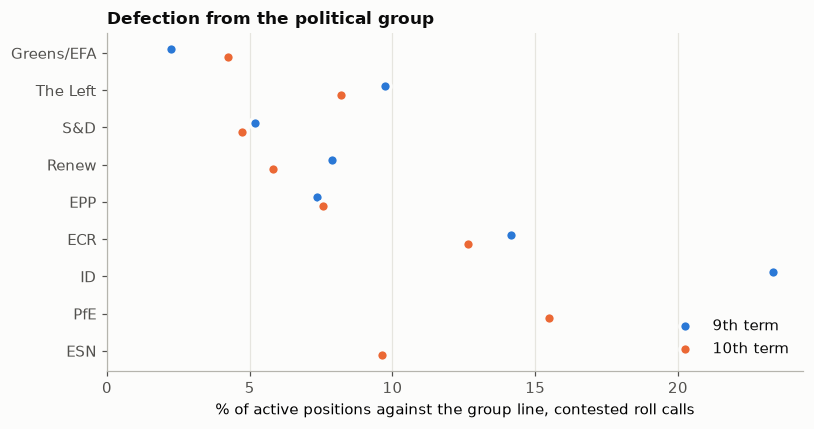

In [3]:
main = grouped.groupby(["group_code", "term"])["defected_group"].mean().unstack()
main = main.reindex(ordered(main.index))
fig, axis = plt.subplots(figsize=(7.5, 4.0))
positions = np.arange(len(main))[::-1]
for term, color, offset in zip(TERMS, SERIES, [0.12, -0.12]):
    axis.scatter(main[term] * 100, positions + offset, s=55, color=color, label=f"{term}th term", zorder=3,
                 edgecolor="#fcfcfb", linewidth=2)
axis.set_yticks(positions, [LABELS[g] for g in main.index])
axis.set_xlabel("% of active positions against the group line, contested roll calls")
axis.set_title("Defection from the political group")
axis.set_xlim(left=0)
axis.legend(loc="lower right")
axis.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**What this shows**

- **Members vote against their group line on 8.8% of their active positions on contested roll calls in the 9th term and 8.2% in the 10th.** Almost every position has a group line (99.9%).
- **A third of defections are abstentions** (32% and 36%). Counting only For against Against, the rate is 5.4% and 4.6%.
- **Defection follows the same pattern as cohesion in the clustering step:**
  - lowest in Greens/EFA (2.2% and 4.2%) and S&D (5.2% and 4.7%);
  - then Renew, the EPP and The Left (5.8% to 9.8%);
  - highest in ECR (14.1% and 12.6%), ID (23.3%) and PfE (15.5%).
  - ESN, the smallest group, is at 9.6%.
- **Abstention is a larger share of defection on the right in the 10th term** (42% to 46% for ECR, PfE and ESN) and in The Left (44% and 47%).

## Defection by country

Countries are spread unevenly across groups, so each country's rate is compared with the rate expected from its members' groups: the group's rate in that term, weighted by how many positions the country's members cast in each group. A ratio above 1 means the country's members defect more than their groups' members on average.

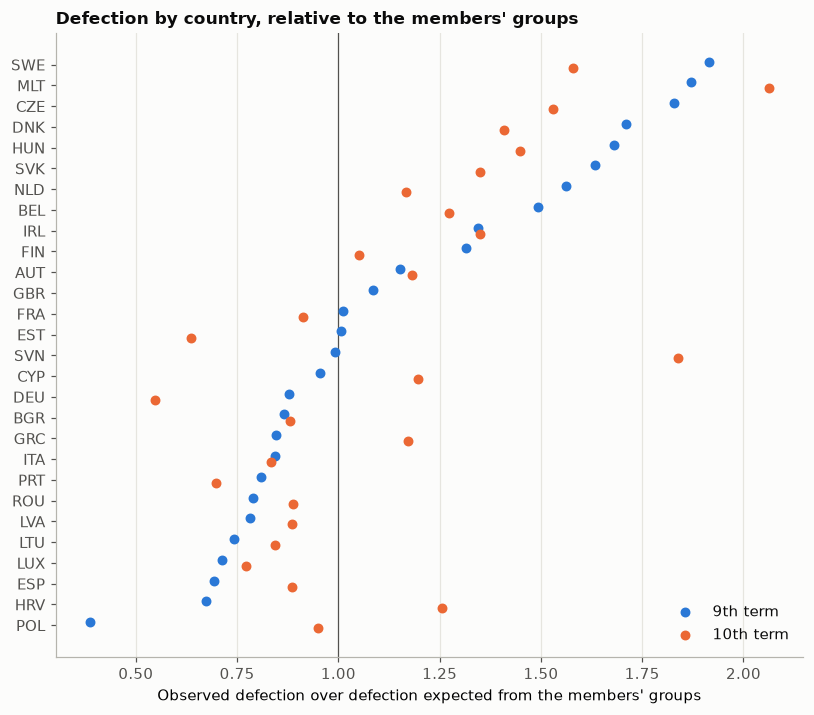

Correlation of the country ratios between terms (Spearman): 0.673


positions           observed        expected         ratio  \
term                 9         10       9      10       9      10     9    
country_code                                                               
SWE            354913.0  122939.0    0.139  0.110    0.073  0.070  1.915   
MLT             92271.0   26501.0    0.109  0.122    0.058  0.059  1.871   
CZE            357773.0  105730.0    0.174  0.182    0.095  0.119  1.828   
DNK            233814.0   85061.0    0.132  0.096    0.077  0.068  1.710   
HUN            193299.0   88830.0    0.110  0.172    0.066  0.119  1.681   
SVK            195004.0   49518.0    0.129  0.093    0.079  0.069  1.633   
NLD            474931.0  176984.0    0.125  0.093    0.080  0.080  1.562   
BEL            351373.0  121342.0    0.147  0.103    0.099  0.081  1.492   
IRL            222329.0   74776.0    0.099  0.091    0.074  0.068  1.346   
FIN            230034.0   82664.0    0.108  0.072    0.082  0.069  1.314   
AUT            321173.0  114651.0    0.099  0.104    0.086  0.088  1.153   
GBR             27472.0       NaN    0.070    NaN    0.064    NaN  1.085   
FRA           1297966.0  440463.0    0.110  0.091    0.109  0.100  1.011   
EST            118793.0   39238.0    0.093  0.044    0.092  0.069  1.007   
SVN            138297.0   50779.0    0.069  0.120    0.070  0.065  0.992   
CYP             95642.0   23932.0    0.071  0.101    0.074  0.084  0.954   
DEU           1559761.0  482762.0    0.066  0.037    0.076  0.067  0.879   
BGR            270333.0   80236.0    0.066  0.068    0.077  0.077  0.866   
GRC            259427.0   83311.0    0.071  0.096    0.083  0.082  0.847   
ITA           1051960.0  405449.0    0.116  0.076    0.138  0.091  0.843   
PRT            358050.0  116351.0    0.053  0.050    0.066  0.071  0.808   
ROU            531089.0  153955.0    0.055  0.066    0.070  0.075  0.789   
LVA            124448.0   49782.0    0.062  0.082    0.079  0.092  0.781   
LTU            173651.0   61899.0    0.050  0.062    0.067  0.074  0.743   
LUX            103192.0   30860.0    0.045  0.049    0.063  0.063  0.712   
ESP            938938.0  317901.0    0.049  0.065    0.070  0.073  0.692   
HRV            169388.0   63473.0    0.049  0.084    0.072  0.067  0.674   
POL            870477.0  293205.0    0.041  0.093    0.105  0.097  0.386   

                     
term             10  
country_code         
SWE           1.579  
MLT           2.063  
CZE           1.530  
DNK           1.408  
HUN           1.448  
SVK           1.350  
NLD           1.168  
BEL           1.274  
IRL           1.349  
FIN           1.052  
AUT           1.182  
GBR             NaN  
FRA           0.914  
EST           0.635  
SVN           1.839  
CYP           1.196  
DEU           0.548  
BGR           0.881  
GRC           1.172  
ITA           0.833  
PRT           0.699  
ROU           0.888  
LVA           0.884  
LTU           0.845  
LUX           0.773  
ESP           0.885  
HRV           1.256  
POL           0.951

In [4]:
with_line = grouped.dropna(subset=["defected_group"])
group_rate = with_line.groupby(["term", "group_code"])["defected_group"].mean().rename("group_rate")
with_line = with_line.join(group_rate, on=["term", "group_code"])
country = with_line.groupby(["term", "country_code"]).agg(
    positions=("defected_group", "size"), observed=("defected_group", "mean"), expected=("group_rate", "mean"))
country["ratio"] = country["observed"] / country["expected"]
wide = country["ratio"].unstack("term")
wide = wide.sort_values(9)
fig, axis = plt.subplots(figsize=(7.5, 6.6))
positions = np.arange(len(wide))
for term, color, offset in zip(TERMS, SERIES, [0.15, -0.15]):
    axis.scatter(wide[term], positions + offset, s=30, color=color, label=f"{term}th term", zorder=3)
axis.axvline(1, color=NEUTRAL, linewidth=0.8)
axis.set_yticks(positions, wide.index)
axis.set_xlabel("Observed defection over defection expected from the members' groups")
axis.set_title("Defection by country, relative to the members' groups")
axis.legend(loc="lower right")
axis.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
print("Correlation of the country ratios between terms (Spearman):",
      round(wide[9].corr(wide[10], method="spearman"), 3))
display(country.unstack("term").round(3).sort_values(("ratio", 9), ascending=False))

**What this shows**

- **Some countries' members defect more than their groups would suggest, in both terms.** Swedish, Maltese, Czech, Danish and Hungarian members defect 1.4 to 2.1 times as often as expected from their groups, and Dutch, Slovak, Belgian and Irish members 1.17 to 1.63 times.
- **The ranking is fairly stable** (Spearman 0.67 between terms), but some countries move a lot:
  - Polish members went from the lowest ratio (0.39) to close to expected (0.95);
  - German members fell from 0.88 to 0.55;
  - Slovenian and Croatian members rose above expected in the 10th term.
- Small countries have few members, so their ratios rest on a handful of people and national parties. Country here mixes national party, electoral system and individual members, and isn't separated from them.

## Defection by kind of roll call and over time

In [5]:
by_part = grouped.groupby(["term", "vote_part"]).agg(
    positions=("defected_group", "size"), defection=("defected_group", "mean"),
    defection_for_against=("defected_group_for_against", "mean"))
display(by_part.round(3))
by_half = grouped.groupby("half").agg(defection=("defected_group", "mean"),
                                      defection_for_against=("defected_group_for_against", "mean"),
                                      rollcalls=("vote_id", "nunique"))
display(by_half.rename(index=half_label).round(3).T)

positions  defection  defection_for_against
term vote_part                                              
9    amendment     6568811      0.085                  0.055
     final          885051      0.095                  0.045
     other          262095      0.064                  0.035
     procedural      94738      0.077                  0.049
     text part     3320780      0.095                  0.054
10   amendment     2418110      0.076                  0.043
     final          369123      0.098                  0.050
     other           53550      0.086                  0.056
     procedural      45176      0.063                  0.038
     text part      860844      0.096                  0.051

half,2019 H2,2020 H1,2020 H2,2021 H1,2021 H2,2022 H1,2022 H2,2023 H1,2023 H2,2024 H1,2024 H2,2025 H1,2025 H2,2026 H1,2026 H2
defection,0.086,0.077,0.084,0.088,0.080,0.093,0.089,0.094,0.096,0.104,0.101,0.083,0.080,0.084,0.075
defection_for_against,0.053,0.045,0.053,0.048,0.042,0.059,0.053,0.057,0.067,0.068,0.056,0.044,0.048,0.046,0.041
rollcalls,499.000,1292.000,3484.000,3488.000,1608.000,2310.000,987.000,1104.000,1574.000,1590.000,489.000,1320.000,1500.000,1824.000,1093.000


**Final votes and votes on parts of a text see more defection than amendments:** 9.5% against 8.5% in the 9th term, and 9.6% to 9.8% against 7.6% in the 10th. On the For/Against measure final votes don't stand out (4.5% against 5.5% for amendments in the 9th term, 5.0% against 4.3% in the 10th), so the extra defection on final votes is largely abstaining.

**Over time, defection rose through the 9th term** from 7.7% (first half of 2020) to 10.4% (first half of 2024, just before the election). It was 10.1% in the first half-year of the 10th term, then fell to between 7.5% and 8.4%.

## How concentrated defection is among members

Members with at least 200 active positions with a group line in the term, so each rate rests on enough votes.

,9th term,10th term
members,818.000,711.000
median rate,0.059,0.069
90th percentile rate,0.204,0.200
share of defections by the top 10% of members,0.348,0.298


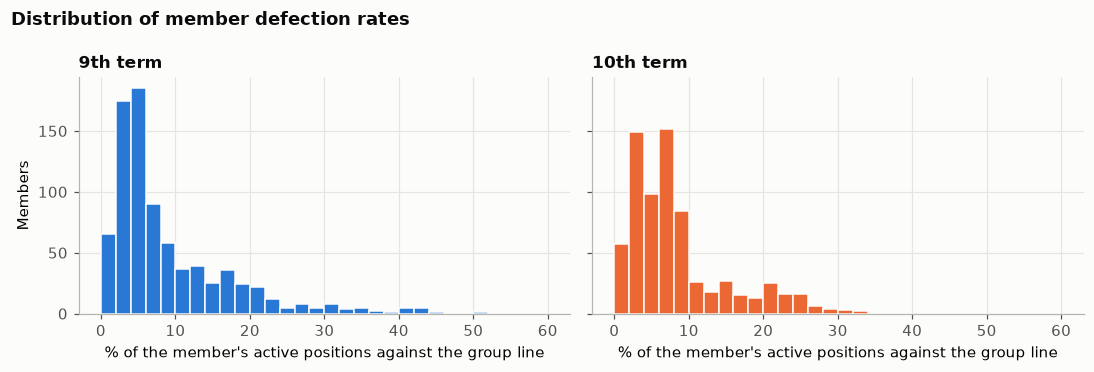

In [6]:
members = with_line.groupby(["term", "member_id"]).agg(
    positions=("defected_group", "size"), defections=("defected_group", "sum"), group=("group_code", lambda s: s.mode()[0]))
members = members[members["positions"] >= 200]
members["rate"] = members["defections"] / members["positions"]
summary = {}
for term in TERMS:
    data = members.loc[term].sort_values("defections", ascending=False)
    top = data.head(int(np.ceil(len(data) * 0.1)))
    summary[f"{term}th term"] = {
        "members": len(data),
        "median rate": data["rate"].median(),
        "90th percentile rate": data["rate"].quantile(0.9),
        "share of defections by the top 10% of members": top["defections"].sum() / data["defections"].sum(),
    }
display(pd.DataFrame(summary).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for axis, term, color in zip(axes, TERMS, SERIES):
    axis.hist(members.loc[term, "rate"] * 100, bins=np.arange(0, 61, 2), color=color, edgecolor="#fcfcfb")
    axis.set_title(f"{term}th term")
    axis.set_xlabel("% of the member's active positions against the group line")
axes[0].set_ylabel("Members")
fig.suptitle("Distribution of member defection rates", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**What this shows**

- **Defection is concentrated.** The median member defects on 5.9% (9th term) and 6.9% (10th) of their positions. One member in ten defects on 20% or more.
- **The 10% of members who defect most account for 35% and 30% of all defections.**

## Sensitivity

In [7]:
checks = {}
for label, frame in [
    ("all roll calls", rows),
    ("contested (2.5%)", contested),
    ("contested (10%)", rows[rows["minority_share"] >= 0.10]),
    ("contested, abstention against (2.5%)", rows[rows["minority_share_with_abstention"] >= 0.025]),
]:
    frame = frame[frame["group_code"] != NON_ATTACHED]
    result = frame.groupby(["term", "group_code"])["defected_group"].mean().unstack("term")
    checks[label] = result.reindex(ordered(result.index))
display(pd.concat(checks, axis=1).rename(index=LABELS).round(3))

all roll calls        contested (2.5%)        contested (10%)  \
term                   9      10               9      10              9    
group_code                                                                 
Greens/EFA          0.021  0.041            0.022  0.042           0.024   
The Left            0.095  0.081            0.098  0.082           0.090   
S&D                 0.048  0.046            0.052  0.047           0.060   
Renew               0.074  0.057            0.079  0.058           0.091   
EPP                 0.069  0.074            0.073  0.076           0.086   
ECR                 0.136  0.124            0.141  0.126           0.141   
ID                  0.230    NaN            0.233    NaN           0.210   
PfE                   NaN  0.153              NaN  0.155             NaN   
ESN                   NaN  0.097              NaN  0.096             NaN   

                  contested, abstention against (2.5%)         
term           10                                   9      10  
group_code                                                     
Greens/EFA  0.043                                0.022  0.042  
The Left    0.079                                0.096  0.082  
S&D         0.050                                0.050  0.047  
Renew       0.061                                0.075  0.057  
EPP         0.080                                0.070  0.074  
ECR         0.128                                0.139  0.125  
ID            NaN                                0.234    NaN  
PfE         0.151                                  NaN  0.154  
ESN         0.091                                  NaN  0.098

**The cutoff and the abstention rule change group rates by at most 2.3 points.** The broad ranking holds, though close neighbours can swap: at 10% in the 9th term, Renew (9.1%) edges past The Left (9.0%). The EPP's and Renew's rates rise somewhat at 10% (to 8.6% and 9.1%) and ID's falls (to 21.0%).

## Summary

- Members vote against their group line on about 8% to 9% of positions on contested roll calls, a third of them abstentions.
- Defection is lowest in Greens/EFA and S&D and highest in ECR, ID and PfE, in both terms.
- Members from some countries (Sweden, Malta, Czechia, Denmark, Hungary) defect well above their groups' rates in both terms.
- Final votes and votes on parts of a text see more defection than amendments.
- Defection rose through the 9th term and fell back in the 10th.
- A tenth of members account for about a third of defections.